# EDA Dataset

In [1]:
import os 
import pandas as pd
import numpy as np 
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
molecular_train_csv = f"/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/train/molecular_train.csv"
clinical_train_csv = f"/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/train/clinical_train.csv"
clinical_test_csv = f"/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/test/clinical_test.csv"
molecular_test_csv = f"/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/test/molecular_test.csv"

target_train_csv = f"/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/train/target_train.csv"

Index(['CHR', 'START', 'END', 'REF', 'ALT', 'GENE', 'PROTEIN_CHANGE', 'EFFECT',
       'VAF', 'DEPTH'],
      dtype='str')
Index(['CENTER', 'BM_BLAST', 'WBC', 'ANC', 'MONOCYTES', 'HB', 'PLT',
       'CYTOGENETICS'],
      dtype='str')
10935
3323
OS_STATUS
1.0    1600
0.0    1573
NaN     150
Name: count, dtype: int64
CENTER
KI       900
DUS      455
PV       316
GESMD    246
RMCN     199
CCH      159
CGM      107
ROM      104
UOB       88
HMS       83
MUV       83
FUCE      73
TUD       73
ICO       71
FLO       68
DUTH      66
UOXF      50
HIAE      47
MSK       37
IHBT      33
VU        33
UMG       26
REL        6
Name: count, dtype: int64


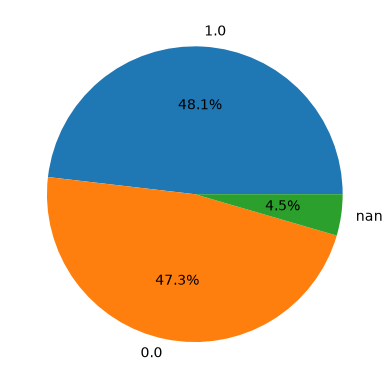

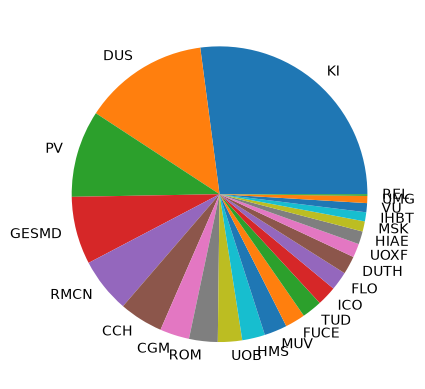

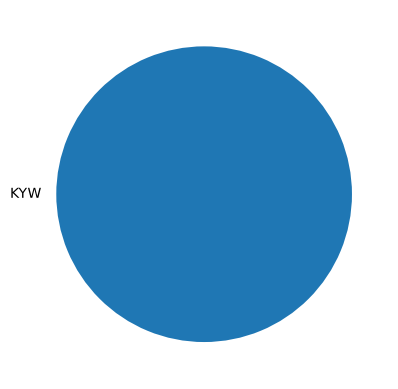

In [3]:
molecular_train_df = pd.read_csv(molecular_train_csv, index_col=0)
clinical_train_df = pd.read_csv(clinical_train_csv, index_col=0)
molecular_test_df = pd.read_csv(molecular_test_csv, index_col=0)
clinical_test_df = pd.read_csv(clinical_test_csv, index_col=0)
target_train_df = pd.read_csv(target_train_csv, index_col=0)
print(molecular_train_df.columns)
print(clinical_train_df.columns)
print(len(molecular_train_df))
print(len(clinical_train_df))

print(target_train_df["OS_STATUS"].value_counts(dropna=False))
os_status_train = target_train_df["OS_STATUS"].value_counts(dropna=False)
plt.figure()
plt.pie(os_status_train.values, labels=os_status_train.index, autopct='%1.1f%%')


plt.figure()
plt.pie(clinical_train_df['CENTER'].value_counts().values, labels=clinical_train_df["CENTER"].value_counts().index)
print(clinical_train_df['CENTER'].value_counts())

plt.figure()
plt.pie(clinical_test_df['CENTER'].value_counts().values, labels=clinical_test_df["CENTER"].value_counts().index)

In [4]:
for c in molecular_train_df.columns:
    print(molecular_train_df[c].value_counts(dropna=True))
    print(f"\n------------------------------------\n")

CHR
4     1699
2     1513
17    1387
X     1204
20     999
21     866
12     596
7      537
5      369
1      365
11     326
15     192
19     155
18     128
9      116
3      115
16      91
22      55
13      42
8       41
10      18
14       4
6        3
Name: count, dtype: int64

------------------------------------

START
74732959.0     485
198266834.0    427
31022441.0     371
90631934.0     143
44514777.0     140
              ... 
39923092.0       1
70468624.0       1
148525920.0      1
106157338.0      1
106157556.0      1
Name: count, Length: 4645, dtype: int64

------------------------------------

END
74732959.0     538
198266834.0    426
31022442.0     369
90631934.0     143
44514777.0     140
              ... 
39923092.0       1
70468624.0       1
148525921.0      1
106157338.0      1
106157556.0      1
Name: count, Length: 4664, dtype: int64

------------------------------------

REF
C                            3199
G                            2965
T                   

## Clinical features distributions


=== BM_BLAST ===
Train -> min: 0.00, max: 91.00, mean: 5.98, std: 7.62, NA: 109
Test  -> min: 0.00, max: 96.00, mean: 12.97, std: 17.28, NA: 115

=== WBC ===
Train -> min: 0.20, max: 154.40, mean: 6.54, std: 10.25, NA: 272
Test  -> min: 0.00, max: 338.10, mean: 7.33, std: 20.67, NA: 112

=== ANC ===
Train -> min: 0.00, max: 109.62, mean: 3.26, std: 5.24, NA: 193
Test  -> min: 0.00, max: 76.14, mean: 2.98, std: 6.48, NA: 141

=== HB ===
Train -> min: 4.00, max: 16.60, mean: 9.89, std: 2.04, NA: 110
Test  -> min: 2.70, max: 23.80, mean: 8.82, std: 2.26, NA: 111

=== PLT ===
Train -> min: 2.00, max: 1451.00, mean: 167.05, std: 149.48, NA: 124
Test  -> min: 0.00, max: 2150.00, mean: 120.63, std: 162.57, NA: 115

=== MONOCYTES ===
Train -> min: 0.00, max: 44.20, mean: 0.96, std: 2.67, NA: 601
Test  -> min: 0.00, max: 25.27, mean: 0.83, std: 2.49, NA: 883


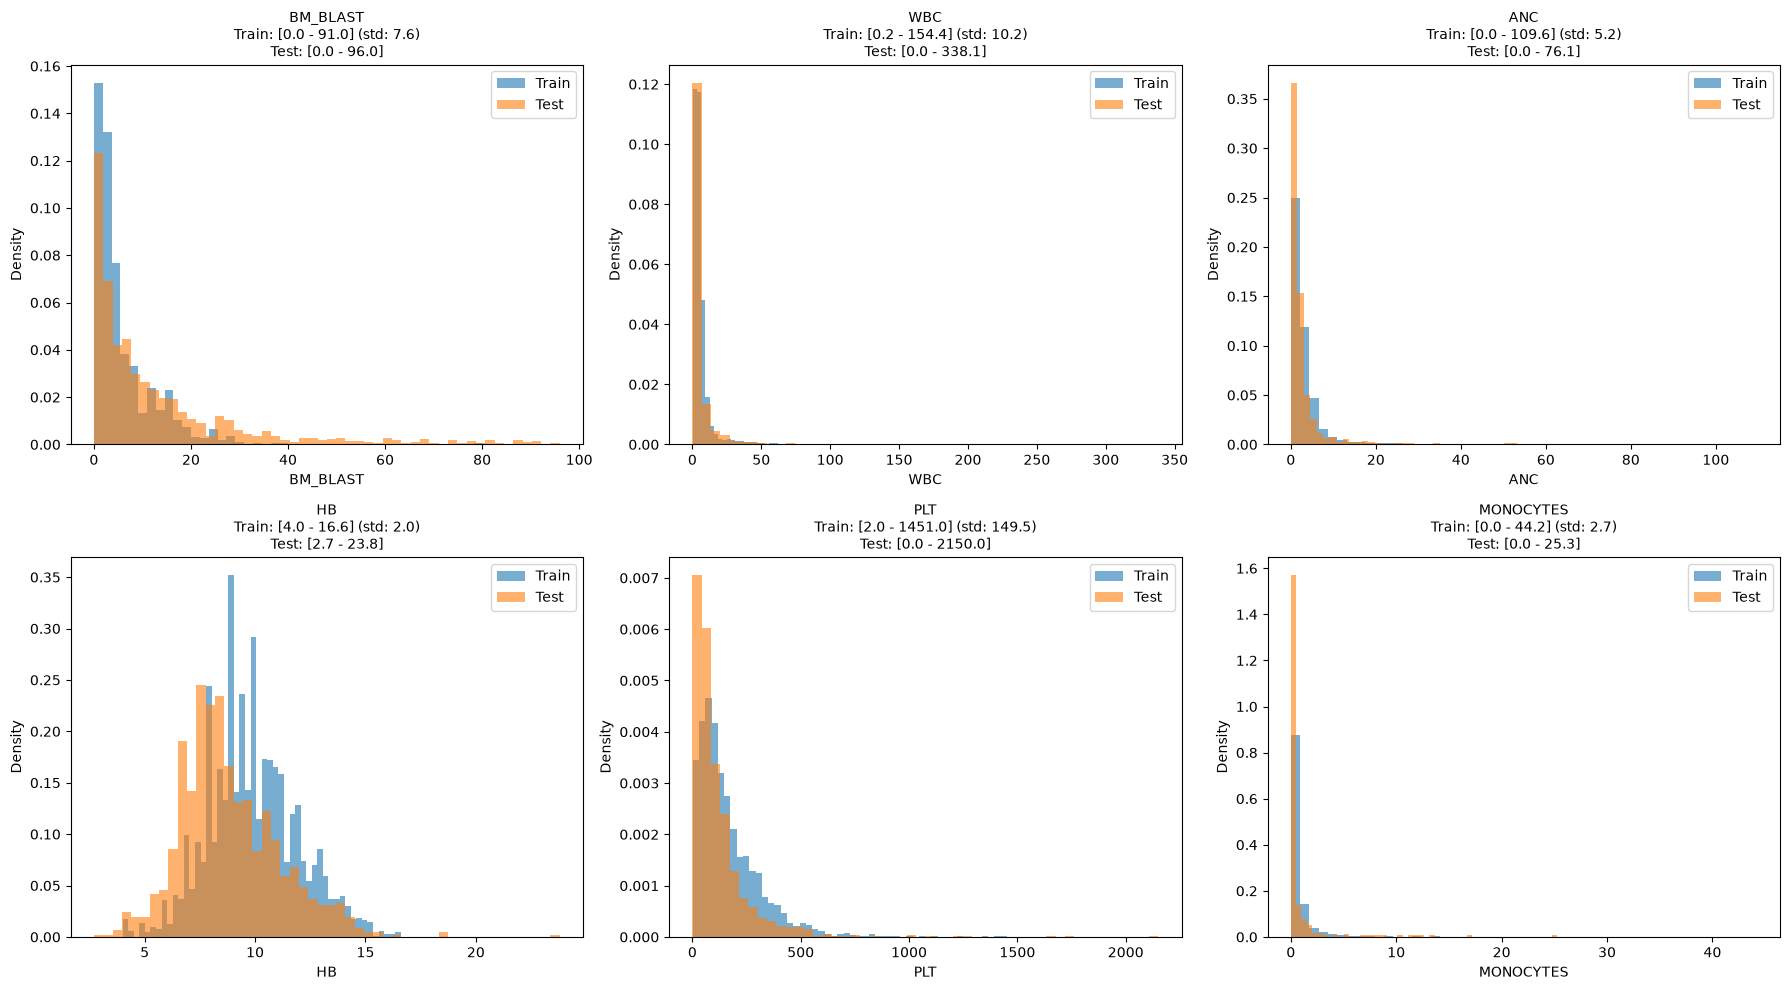

In [5]:

cols = ["BM_BLAST", "WBC", "ANC", "HB", "PLT", "MONOCYTES"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, c in enumerate(cols):
    ax = axes[i] 
    
    tr_s = clinical_train_df[c].describe()
    te_s = clinical_test_df[c].describe()

    print(f"\n=== {c} ===")
    print(
        f"Train -> min: {tr_s['min']:.2f}, max: {tr_s['max']:.2f}, mean: {tr_s['mean']:.2f}, std: {tr_s['std']:.2f}, NA: {clinical_train_df[c].isna().sum()}"
    )
    print(
        f"Test  -> min: {te_s['min']:.2f}, max: {te_s['max']:.2f}, mean: {te_s['mean']:.2f}, std: {te_s['std']:.2f}, NA: {clinical_test_df[c].isna().sum()}"
    )

    ax.hist(
        clinical_train_df[c].dropna(),
        bins=50,
        alpha=0.6,
        label="Train",
        density=True,
    )
    ax.hist(
        clinical_test_df[c].dropna(),
        bins=50,
        alpha=0.6,
        label="Test",
        density=True,
    )


    ax.set_title(
        f"{c}\nTrain: [{tr_s['min']:.1f} - {tr_s['max']:.1f}] (std: {tr_s['std']:.1f})\nTest: [{te_s['min']:.1f} - {te_s['max']:.1f}]",
        fontsize=10
    )
    ax.set_xlabel(c)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()

plt.show()

### Kaplan-Meier

In [6]:
clean_target_df = target_train_df.dropna(subset=['OS_YEARS', 'OS_STATUS'])
print(f"Len de init target:{len(target_train_df)}")
print(f"Len de clean target : {len(clean_target_df)}")
print(f"NA : {len(target_train_df) - len(clean_target_df)}")

Len de init target:3323
Len de clean target : 3173
NA : 150


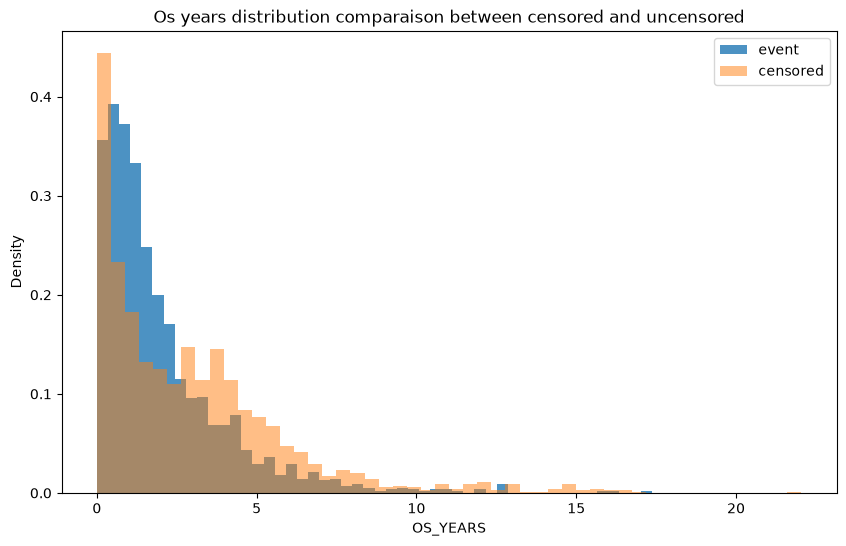

In [7]:
a_clean_target_df = clean_target_df[clean_target_df["OS_STATUS"] == 1]
b_clean_target_df = clean_target_df[clean_target_df["OS_STATUS"] == 0]

plt.figure(figsize=(10, 6))

plt.hist(a_clean_target_df['OS_YEARS'], bins=50, alpha=0.8, label="event", density=True)
plt.hist(b_clean_target_df['OS_YEARS'], bins=50, alpha=0.5, label='censored', density=True)

plt.title('Os years distribution comparaison between censored and uncensored')
plt.xlabel('OS_YEARS')
plt.ylabel('Density')
plt.legend()
plt.show()

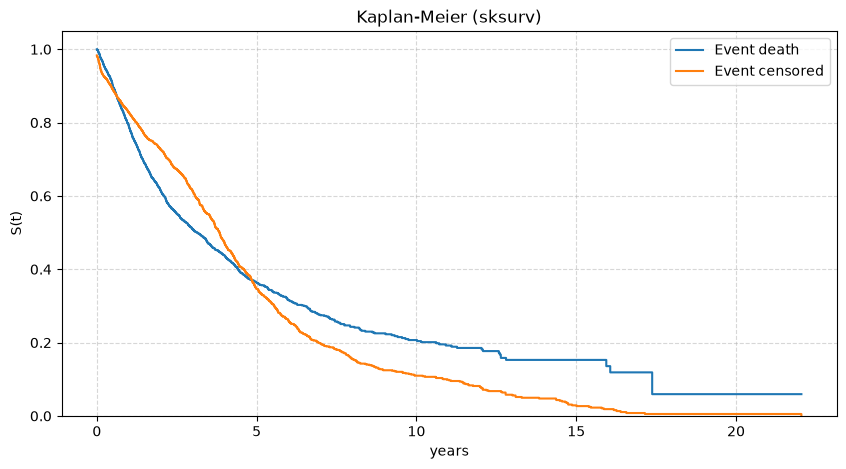

In [8]:
# check the censored

from sksurv.nonparametric import kaplan_meier_estimator

time, prob_survival = kaplan_meier_estimator(
    clean_target_df["OS_STATUS"].astype(bool),
    clean_target_df["OS_YEARS"]


)


plt.figure(figsize=(10,5))

plt.step(time, prob_survival, where="post", label="Event death")
plt.ylim(0, 1.05)
plt.title("Kaplan-Meier (sksurv)")
plt.xlabel("years")
plt.ylabel("S(t)")
plt.grid(True, linestyle="--", alpha=0.5)




time, prob_survival = kaplan_meier_estimator(
    clean_target_df["OS_STATUS"].astype(bool) == 0,
    clean_target_df["OS_YEARS"]


)

plt.step(time, prob_survival, where="post", label="Event censored")
plt.legend()
plt.show()

### Proportional hazards model: Cox

Risk at a time t for the subject i is defines as :
$\lambda(t| X_i) = \lambda_0 \exp(\beta_1 X_{i1} + ... + \beta_p X_{ip}) = \lambda_0 \exp(\beta X)$

(from challenge)
To account for censoring in survival analysis, we use a Cox Proportional Hazards (Cox PH) model, a widely used method that estimates the effect of covariates on survival times without assuming a specific baseline survival distribution. The Cox PH model is based on the hazard function, $h(t | X)$, which represents the instantaneous risk of an event (e.g., death) at time $t$ given covariates $X$. The model assumes that the hazard can be expressed as:

$$h(t | X) = h_0(t) \exp(\beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p)$$


where $h_0(t)$ is the baseline hazard function, and $\beta$ values are coefficients for each covariate, representing the effect of $X$ on the hazard. Importantly, the proportional hazards assumption implies that the hazard ratios between individuals are constant over time. This approach effectively leverages both observed and censored survival times, making it a more suitable method for survival data compared to standard regression techniques that ignore censoring.



From this model, the goal is to maximize the partial likelyhood for the order of events. We suppose M samples for which events have already occured and note the time $Y_1 < ... < Y_M$

We have $L_i(\beta) = \frac{\lambda(Y_i | X_i)}{\sum_{j=i}^{N} \lambda(Y_j | X_i)}$ which is the proba that for the event that occurs at time $Y_i$, the subject $i$ is the one concerned by the event.


For independant subject, $L(\beta) = \prod L_i(\beta)$ and then the log partial likelyhood if $l(\beta) = \sum_{i:C_i=1} (X_i \beta - \log(\sum_{j:Y_j>y_i} \theta_j))$

The following code will find $\hat\beta$ that maximize this quantity

In [9]:
clean_target_df["OS_YEARS"] = pd.to_numeric(clean_target_df["OS_YEARS"], errors='coerce')
clean_target_df["OS_STATUS"] = clean_target_df["OS_STATUS"].astype(bool)

In [10]:
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored , concordance_index_ipcw
from sklearn.impute import SimpleImputer
from sksurv.util import Surv


In [11]:
features = ["BM_BLAST", "HB", "PLT"]
target = ['OS_YEARS', 'OS_STATUS']
print(clean_target_df[['OS_STATUS', 'OS_YEARS']].dtypes)

X = clinical_train_df[clinical_train_df.index.isin(clean_target_df.index)][features]
y = Surv.from_dataframe('OS_STATUS', 'OS_YEARS', clean_target_df)


OS_STATUS       bool
OS_YEARS     float64
dtype: object


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [13]:
# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[['BM_BLAST', 'HB', 'PLT']] = imputer.fit_transform(X_train[['BM_BLAST', 'HB', 'PLT']])
X_test[['BM_BLAST', 'HB', 'PLT']] = imputer.transform(X_test[['BM_BLAST', 'HB', 'PLT']])

In [14]:
# Initialize and train the Cox Proportional Hazards model
cox = CoxPHSurvivalAnalysis()
cox.fit(X_train, y_train)

# Evaluate the model using Concordance Index IPCW
cox_cindex_train = concordance_index_ipcw(y_train, y_train, cox.predict(X_train), tau=7)[0]
cox_cindex_test = concordance_index_ipcw(y_train, y_test, cox.predict(X_test), tau=7)[0]
print(f"Cox Proportional Hazard Model Concordance Index IPCW on train: {cox_cindex_train:.2f}")
print(f"Cox Proportional Hazard Model Concordance Index IPCW on test: {cox_cindex_test:.2f}")

Cox Proportional Hazard Model Concordance Index IPCW on train: 0.66
Cox Proportional Hazard Model Concordance Index IPCW on test: 0.66


## Cytogenetics

In [16]:
cytogenetics_df = pd.read_csv("/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/cytogenetics_train.csv", index_col=0)

In [17]:
cytogenetics_df.head()

,cyto_is_unknown,cyto_is_normal,cyto_sex_F,cyto_sex_M,cyto_sex_Unknown,cyto_chromosome_count,cyto_t_8_21,cyto_inv_16,cyto_t_15_17,cyto_monosomy_7,cyto_monosomy_5,cyto_trisomy_8,cyto_complexity_score,cyto_is_complex
ID,,,,,,,,,,,,,,
P132697,0,0,False,True,False,46.0,0,0,0,0,0,0,1,0
P132698,0,1,True,False,False,46.0,0,0,0,0,0,0,0,0
P116889,0,0,False,True,False,46.0,0,0,0,0,0,0,1,0
P132699,0,0,False,True,False,46.0,0,0,0,0,0,0,1,0
P132700,0,0,True,False,False,46.0,0,0,0,0,0,0,1,0


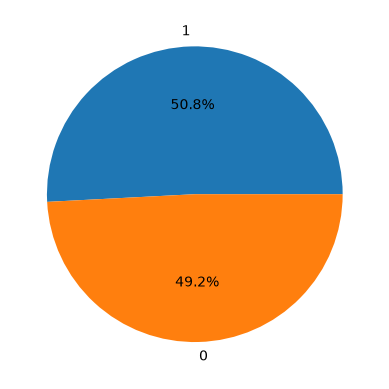

In [18]:
is_normal_series = cytogenetics_df["cyto_is_normal"]
plt.figure()
plt.pie(is_normal_series.value_counts().values, labels=is_normal_series.value_counts().index, autopct='%1.1f%%')

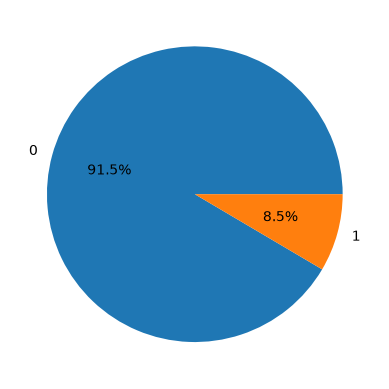

In [19]:
is_complex_series = cytogenetics_df["cyto_is_complex"]
plt.figure()
plt.pie(is_complex_series.value_counts().values, labels=is_complex_series.value_counts().index, autopct='%1.1f%%')

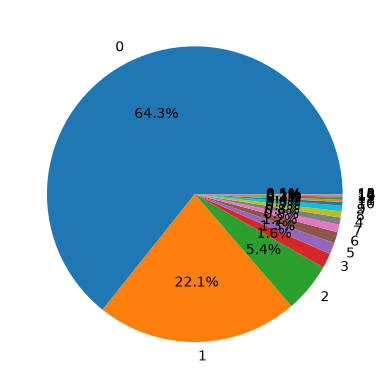

In [20]:
complexity_score_series = cytogenetics_df["cyto_complexity_score"]
plt.figure() 
plt.pie(complexity_score_series.value_counts().values, labels=complexity_score_series.value_counts().index, autopct='%1.1f%%')

In [21]:
complexity_score_series.value_counts()

cyto_complexity_score
0     2136
1      733
2      180
3       54
5       42
6       40
7       28
4       26
8       22
9       21
10      13
11       8
12       7
13       4
14       3
16       2
18       2
15       2
Name: count, dtype: int64

31
30


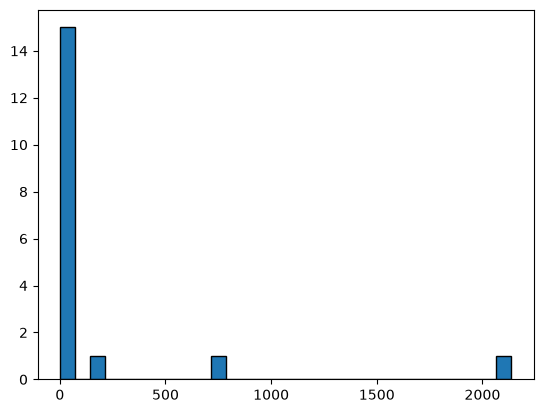

In [22]:
hist, bins = np.histogram(complexity_score_series.value_counts().values, bins=30)
width = np.diff(bins)
print(len(bins))
print(len(hist))

plt.bar(bins[:-1], hist, width=width, align='edge', edgecolor='black')
plt.show()

<Axes: xlabel='cyto_complexity_score', ylabel='Count'>

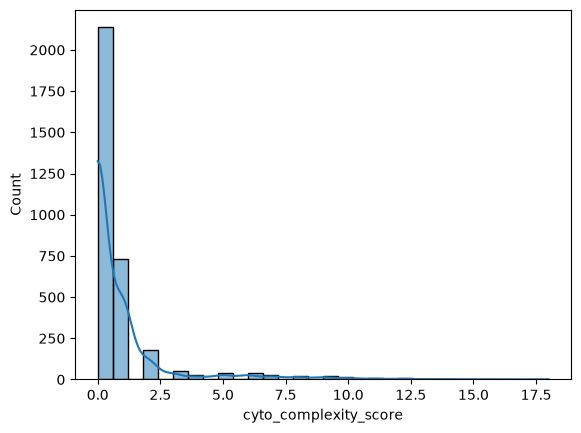

In [23]:
import seaborn as sns

sns.histplot(complexity_score_series, bins=30, kde=True)


<Axes: xlabel='cyto_is_normal', ylabel='Count'>

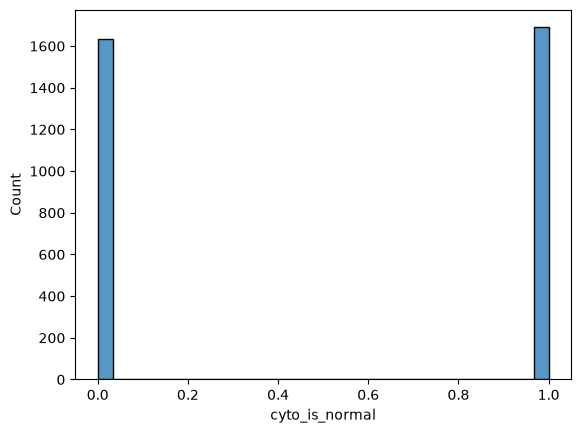

In [24]:
sns.histplot(cytogenetics_df["cyto_is_normal"], bins=30)

In [25]:
merge_df = clinical_train_df[clinical_train_df.index.isin(clean_target_df.index)].merge(
    cytogenetics_df[cytogenetics_df.index.isin(clean_target_df.index)]['cyto_complexity_score'],
    left_index=True,
    right_index=True,
    how='left'
)
merge_df.head

<bound method NDFrame.head of         CENTER  BM_BLAST     WBC   ANC  MONOCYTES    HB    PLT  \
ID                                                               
P132697    MSK      14.0    2.80  0.20       0.70   7.6  119.0   
P132698    MSK       1.0    7.40  2.40       0.10  11.6   42.0   
P116889    MSK      15.0    3.70  2.10       0.10  14.2   81.0   
P132699    MSK       1.0    3.90  1.90       0.10   8.9   77.0   
P132700    MSK       6.0  128.00  9.70       0.90  11.1  195.0   
...        ...       ...     ...   ...        ...   ...    ...   
P121826     VU       1.0    2.50  1.02       0.20  10.2   78.0   
P121827     VU       1.5    8.10  2.66       0.45  11.3   40.0   
P121830     VU       0.0    1.80  0.55       0.29   9.4   86.0   
P121853     VU       5.0    1.37  0.37       0.11  11.4  102.0   
P121834     VU       0.0    2.70  0.72       0.23   8.2  239.0   

                                              CYTOGENETICS  \
ID                                               

In [26]:
features = ["BM_BLAST", "HB", "PLT", "cyto_complexity_score"]
X = merge_df[features]



In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[['BM_BLAST', 'HB', 'PLT']] = imputer.fit_transform(X_train[['BM_BLAST', 'HB', 'PLT']])
X_test[['BM_BLAST', 'HB', 'PLT']] = imputer.transform(X_test[['BM_BLAST', 'HB', 'PLT']])
# Initialize and train the Cox Proportional Hazards model
cox = CoxPHSurvivalAnalysis()
cox.fit(X_train, y_train)

# Evaluate the model using Concordance Index IPCW
cox_cindex_train = concordance_index_ipcw(y_train, y_train, cox.predict(X_train), tau=7)[0]
cox_cindex_test = concordance_index_ipcw(y_train, y_test, cox.predict(X_test), tau=7)[0]
print(f"Cox Proportional Hazard Model Concordance Index IPCW on train: {cox_cindex_train:.2f}")
print(f"Cox Proportional Hazard Model Concordance Index IPCW on test: {cox_cindex_test:.2f}")

Cox Proportional Hazard Model Concordance Index IPCW on train: 0.68
Cox Proportional Hazard Model Concordance Index IPCW on test: 0.68


In [28]:
molecular_train_df = molecular_train_df[molecular_train_df.isin(clean_target_df.index)]

In [29]:
len(molecular_train_df)

10935

In [30]:
len(set(molecular_train_df.index))

3026

In [32]:
len(target_train_df) - len(set(molecular_train_df.index))

297

In [33]:
len(target_train_df) 

3323

In [46]:
molecular_train_df = pd.read_csv("/home/joh/Sync/pro/data-challenge_ens/qrt_leukemia/data/raw/train/molecular_train.csv", index_col=0)
molecular_train_df = molecular_train_df[molecular_train_df.index.isin(clean_target_df.index)]

In [58]:
d = molecular_train_df["GENE"].value_counts(dropna=False)
print(len(d))


unique_uid = list(set(molecular_train_df.index))


d = molecular_train_df.loc[unique_uid, 'GENE'].value_counts(dropna=False)
print(len(d))

121
121


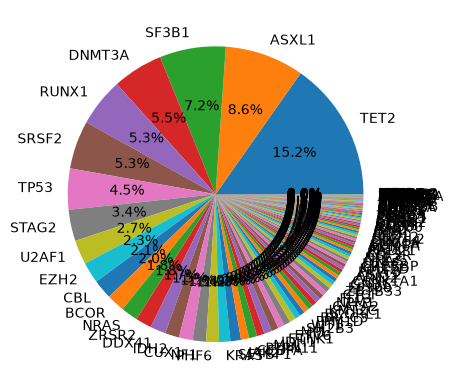

In [50]:
plt.figure()
plt.pie(molecular_train_df["GENE"].value_counts().values, labels=molecular_train_df["GENE"].value_counts().index, autopct='%1.1f%%')
plt.show()

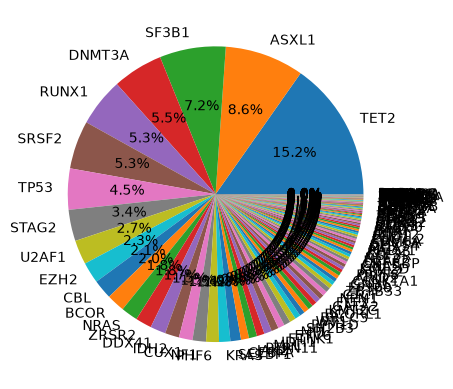

In [59]:
plt.figure()
plt.pie(molecular_train_df.loc[unique_uid, "GENE"].value_counts().values, labels=molecular_train_df.loc[unique_uid, "GENE"].value_counts().index, autopct='%1.1f%%')
plt.show()

In [62]:
d = molecular_train_df["GENE"].value_counts()

d = sorted(d.items(), key=lambda x: x[1], reverse=True)
print(d)

top_keys= d[:20]
print(top_keys)

[('TET2', 1608), ('ASXL1', 912), ('SF3B1', 762), ('DNMT3A', 581), ('RUNX1', 558), ('SRSF2', 556), ('TP53', 474), ('STAG2', 361), ('U2AF1', 280), ('EZH2', 243), ('CBL', 224), ('BCOR', 209), ('NRAS', 193), ('ZRSR2', 186), ('DDX41', 178), ('IDH2', 163), ('CUX1', 157), ('NF1', 155), ('PHF6', 148), ('KRAS', 130), ('SETBP1', 122), ('JAK2', 93), ('CEBPA', 93), ('PTPN11', 88), ('MLL', 88), ('IDH1', 84), ('ETNK1', 75), ('ETV6', 75), ('MPL', 71), ('SH2B3', 64), ('WT1', 60), ('PPM1D', 60), ('BRCC3', 59), ('BCORL1', 58), ('KMT2C', 56), ('GATA2', 55), ('NPM1', 55), ('FLT3', 55), ('CTCF', 47), ('ZBTB33', 45), ('EP300', 43), ('GNB1', 42), ('CSNK1A1', 41), ('ARID2', 37), ('ASXL2', 36), ('PRPF8', 36), ('KMT2D', 32), ('CREBBP', 31), ('U2AF2', 31), ('GNAS', 31), ('NFE2', 31), ('CSF3R', 28), ('KIT', 27), ('RAD21', 26), ('MGA', 25), ('KDM6A', 25), ('SMC1A', 25), ('DDX54', 25), ('LUC7L2', 24), ('SUZ12', 22), ('EED', 22), ('IRF1', 21), ('BRAF', 21), ('ATRX', 19), ('RAD50', 18), ('STAT3', 17), ('DDX4', 17), (

In [65]:
tmp = molecular_train_df.reset_index()
f = tmp.groupby("GENE")["ID"].nunique()

In [71]:
print(tmp.groupby("GENE")["ID"].value_counts())

GENE    ID     
ABL1    P120995    1
        P122448    1
ARID1A  P118222    2
        P100343    1
        P105722    1
                  ..
ZRSR2   P121134    1
        P122393    1
        P131851    1
        P102626    1
        P103051    1
Name: count, Length: 9050, dtype: int64


In [73]:
print(f)

GENE
ABL1        2
ARID1A      7
ARID2      37
ASXL1     859
ASXL2      34
         ... 
WT1        48
ZBTB33     45
ZMYM3       8
ZNF318      1
ZRSR2     167
Name: ID, Length: 121, dtype: int64


In [72]:
print(dict(sorted(f.items(), key=lambda x: x[1], reverse=True)[:20]))

{'TET2': 1001, 'ASXL1': 859, 'SF3B1': 727, 'SRSF2': 551, 'DNMT3A': 514, 'RUNX1': 448, 'TP53': 368, 'STAG2': 288, 'U2AF1': 277, 'EZH2': 209, 'BCOR': 179, 'CBL': 176, 'NRAS': 167, 'ZRSR2': 167, 'IDH2': 163, 'CUX1': 124, 'NF1': 121, 'KRAS': 120, 'SETBP1': 115, 'DDX41': 113}
